In [4]:
!pip install pdbparser biopython mygene openpyxl freesasa py3Dmol -q
import sys
!{sys.executable} -m pip install pymol-open-source -q

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 270.1/270.1 kB 6.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 161.9/161.9 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 50.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.0/52.0 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 28.2 MB/s eta 0:00:00


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import subprocess
import json

pdb_file='Mouse STING homodimer(ranked_0).pdb'

In [7]:
for readout in ['Initial_vs_Primary_4T1','Initial_vs_Primary_EO771',
                'Primary_vs_Met_4T1', 'Tail_Vein_vs_Met_4T1', 'Initial_vs_Tail_Vein_EO771']:

  # Load weight
  weights = pd.read_csv(''.join(['inferred_weights_',readout,'.csv']))
  weights.columns = ['position', 'additive','interaction']

  for effect in ['additive','interaction']:

    # Use additive weight
    residue_scores = weights[effect]
    residue_scores.index = weights.index +1

    # Plot
    png_outfilename = ''.join(['inferred_weights_3dplot_',readout,
                               '_',effect,'.png'])

    # Colorbar min and max
    if effect=='additive':
      if readout=="Initial_vs_Primary_4T1":
        score_range = 0.2
      if readout=="Initial_vs_Primary_EO771":
        score_range = 0.2
      if readout=="Primary_vs_Met_4T1":
        score_range = 0.2
      if readout=="Tail_Vein_vs_Met_4T1":
        score_range = 0.2
      if readout=="Initial_vs_Tail_Vein_EO771":
        score_range = 0.05


    if effect=='interaction':
      if readout=="Initial_vs_Primary_4T1":
        score_range = 0.5
      if readout=="Initial_vs_Primary_EO771":
        score_range = 0.5
      if readout=="Primary_vs_Met_4T1":
        score_range = 0.5
      if readout=="Tail_Vein_vs_Met_4T1":
        score_range = 0.5
      if readout=="Initial_vs_Tail_Vein_EO771":
        score_range = 0.025


    min_score = -score_range
    max_score = score_range

    # Run the coloring script and capture its output
    result = subprocess.run(
        ['python3', 'color_sting.py','--scores',
        json.dumps(residue_scores.to_dict()), '--cmap', 'RdBu_r',
        '--vlim', str(min_score), str(max_score), # Pass actual min and max as strings
        '--png', png_outfilename,
        '--pdb', pdb_file],
        capture_output=True, text=True)

(array([ 1.,  0.,  0.,  0.,  0.,  1.,  0.,  0.,  0.,  0.,  5.,  0.,  0.,
         0.,  0.,  2.,  0.,  0.,  0.,  0.,  0.,  2.,  0.,  0.,  0.,  0.,
         8.,  0.,  0.,  0.,  0., 20.,  0.,  0.,  0.,  0., 33.,  0.,  0.,
         0.,  0.,  0., 43.,  0.,  0.,  0.,  0., 44.,  0.,  0.,  0.,  0.,
        49.,  0.,  0.,  0.,  0., 47.,  0.,  0.,  0.,  0.,  0., 39.,  0.,
         0.,  0.,  0., 30.,  0.,  0.,  0.,  0., 19.,  0.,  0.,  0.,  0.,
        18.,  0.,  0.,  0.,  0.,  0.,  7.,  0.,  0.,  0.,  0.,  5.,  0.,
         0.,  0.,  0.,  2.,  0.,  0.,  0.,  0.,  3.]),
 array([-0.027  , -0.02681, -0.02662, -0.02643, -0.02624, -0.02605,
        -0.02586, -0.02567, -0.02548, -0.02529, -0.0251 , -0.02491,
        -0.02472, -0.02453, -0.02434, -0.02415, -0.02396, -0.02377,
        -0.02358, -0.02339, -0.0232 , -0.02301, -0.02282, -0.02263,
        -0.02244, -0.02225, -0.02206, -0.02187, -0.02168, -0.02149,
        -0.0213 , -0.02111, -0.02092, -0.02073, -0.02054, -0.02035,
        -0.02016, -0.01997

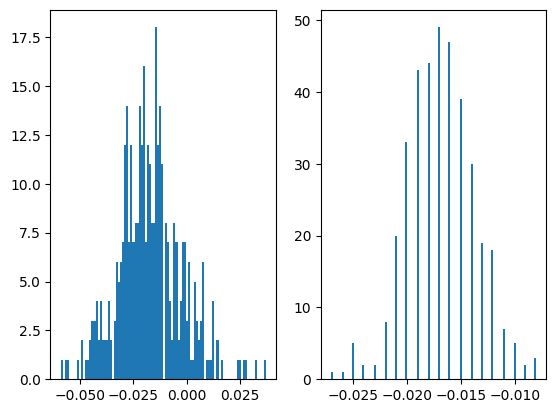

In [3]:
# This cell plots histograms of weights to set set colorbar limits
readout='Initial_vs_Tail_Vein_EO771'
# Load weights
weights = pd.read_csv(''.join(['inferred_weights_',readout,'.csv']));
weights.columns = ['position', 'additive','interaction']

plt.subplot(1,2,1)
plt.hist(weights.additive,100)
plt.subplot(1,2,2)
plt.hist(weights.interaction,100)

